# MNIST 이미지 분류

완전연결 신경망과 합성곱 신경망의 학습 곡선 및 예측 결과 비교. 학습 데이터 60,000장 중 마지막 5,000장을 검증에 사용하고 테스트 10,000장은 분리.

기본 모델은 10 epochs, 확장 CNN은 30 epochs로 학습하므로 구조만의 효과를 분리한 실험은 아님.

## MNIST 데이터셋 불러오기


In [1]:
# MNIST 데이터셋 불러오기
import numpy as np
from tensorflow.keras.datasets import mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)


(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [2]:
y_train.shape


(60000,)

In [3]:
y_train


array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

## 입력 이미지 확인

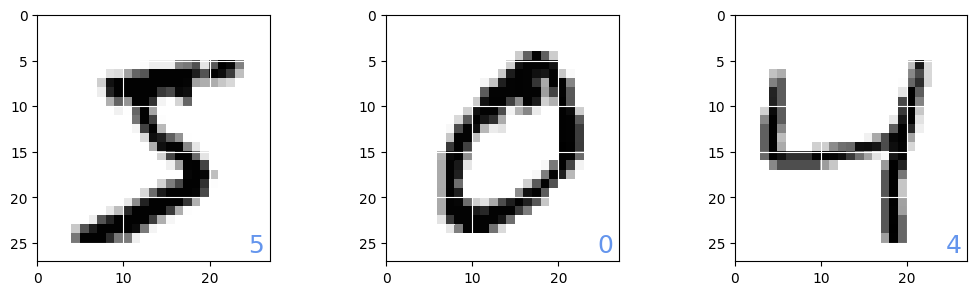

In [4]:
import numpy as np
import matplotlib.pyplot as plt 
%matplotlib inline

plt.figure(figsize =(12, 3.2)) 
plt.subplots_adjust(wspace=0.5) 
plt.gray()

for id in range(3):
    plt.subplot(1, 3, id + 1)
    img = x_train[id, :, :]
    plt.pcolor(255 - img)
    plt.text(24.5, 26, "%d" % y_train[id],
             color='cornflowerblue', fontsize=18) 
    plt.xlim(0, 27)
    plt.ylim(27, 0)

    plt.grid('on', color='white') 
plt.show()


## MLP 입력 데이터 준비


In [5]:
# one-hot encoding 을 위한 모듈 추가
from tensorflow.keras.utils import to_categorical

# 훈련(학습) 데이터 준비
x_train = x_train.reshape(60000, 784) # (60000, 28, 28) 인 mnist 훈련 데이터셋을 (60000, 784) 으로 변환
x_train = x_train.astype('float32') # 입력 데이터를 실수로 처리하기 위해 int 를 float 형으로 변환
x_train = x_train / 255 # 픽셀 값을 0 ~ 1 까지 값으로 변환(정규화, normalization)
num_classes = 10 # 10개의 분류 (0 ~ 9)
y_train = to_categorical(y_train, num_classes) # one-hot encoding

# 테스트 데이터 준비
x_test = x_test.reshape(10000, 784)
x_test = x_test.astype('float32')
x_test = x_test / 255
y_test = to_categorical(y_test, num_classes)


In [6]:
y_train[2]


array([0., 0., 0., 0., 1., 0., 0., 0., 0., 0.], dtype=float32)

## 2층 피드 포워드 네트워크 모델 #1


In [7]:
# 필기체 숫자인식을 위한 2층 피드포워드 네트워크
# 은닉층 뉴런수 M=16개, 활성화 함수는 시그모이드 함수
# 출력층 뉴런수 K=10개, 활성화 함수는 소프트맥스 함수

np.random.seed(1)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.optimizers import Adam

model = Sequential()
model.add(Dense(16, input_dim=784, activation='sigmoid'))
model.add(Dense(10, activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])


In [8]:
model.summary()


Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense (Dense)               (None, 16)                12560     


 dense_1 (Dense)             (None, 10)                170       


Total params: 12,730


Trainable params: 12,730


Non-trainable params: 0


_________________________________________________________________


In [9]:
# 학습
import time

start_time = time.time()
history = model.fit(x_train, y_train, epochs=10, batch_size=1000, verbose=0,
                    validation_split=1/12)
print("computation time: {:.3f} sec".format(time.time() - start_time))

print('\n')
score = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss: ", score[0])
print("Test Accuracy: ", score[1])


computation time: 1.849 sec




Test Loss:  0.5462732911109924
Test Accuracy:  0.8944000005722046


## 학습 곡선과 검증 오차

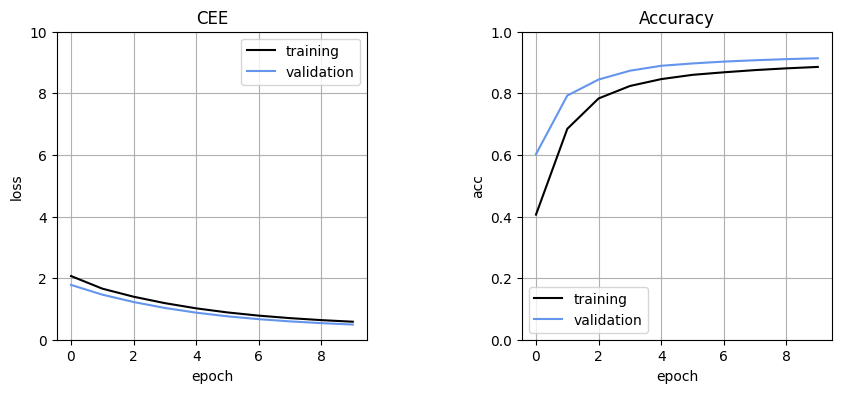

In [10]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize = (10, 4))
plt.subplots_adjust(wspace = 0.5)

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label = 'training', color = 'black')
plt.plot(history.history['val_loss'], label = 'validation', color ='cornflowerblue')
plt.ylim(0, 10)
plt.legend()
plt.grid()
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('CEE')

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label = 'training', color = 'black')
plt.plot(history.history['val_accuracy'], label = 'validation', color = 'cornflowerblue')
plt.ylim(0, 1)
plt.legend()
plt.grid()
plt.xlabel('epoch')
plt.ylabel('acc')
plt.title('Accuracy')
plt.show()


## 완전연결 신경망 예측 결과

  1/313 [..............................] - ETA: 30s

119/313 [==========>...................] - ETA: 0s 

254/313 [=======================>......] - ETA: 0s

313/313 [==============================] - 0s 395us/step


Total wrong answer:  10 / 96


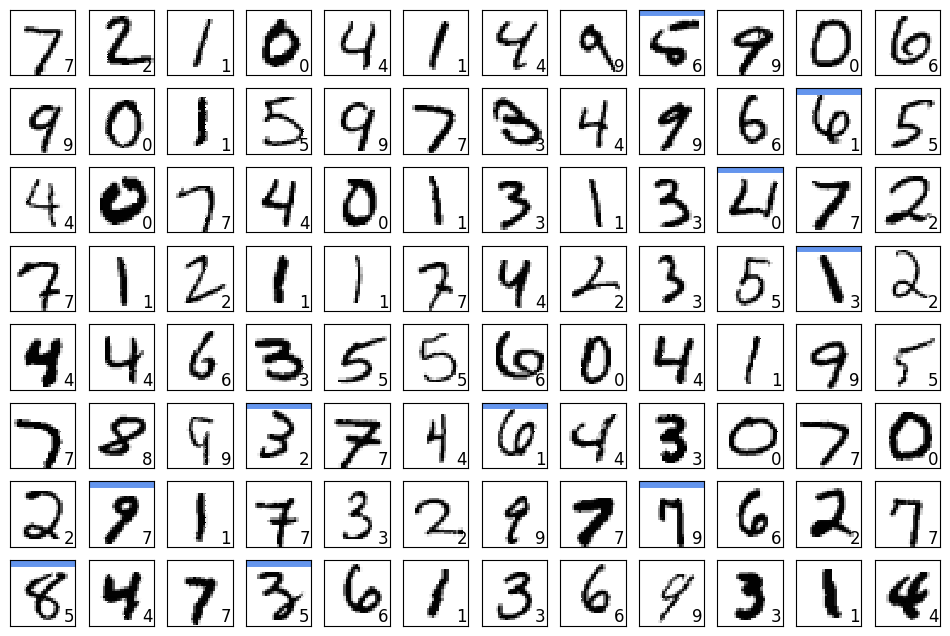

In [11]:
# 실제 테스트 데이터를 입력했을 대 모델의 출력
def show_prediction():
    n_show = 96
    y = model.predict(x_test) # (A) x_test 전체에 대한 모델의 출력 y 를 얻을 수 있다.
    plt.figure(figsize = (12, 8))
    plt.gray()
    wrong_answer = 0
    # 그중 처음 96개 분량을 이미지로 출력, 파란색 가로줄은 오인식일 경우를 나타낸다.
    for i in range(n_show):
        plt.subplot(8, 12, i + 1)
        x = x_test[i, :]
        x = x.reshape(28, 28)
        plt.pcolor(1 - x)
        wk = y[i, :] # i 번째 출력 레이블을 가져온다 
        prediction = np.argmax(wk)  # wk 에서 값이 가장 큰 요소의 인덱스 값을 가져온다 = 정답 레이블의 번호 0 ~ 9 중 하나
        plt.text(22, 25.5, "%d" % prediction, fontsize = 12)
        
        if prediction != np.argmax(y_test[i, :]): # 예측 결과(prediction) 과 y_test가 일치하지 않은 경우 상단에 파란색 줄을 긋는다.
            plt.plot([0, 27], [1, 1], color ='cornflowerblue', linewidth = 5)
            wrong_answer = wrong_answer + 1
            
        plt.xlim(0, 27)
        plt.ylim(27, 0)
        plt.xticks([], "")
        plt.yticks([], "")
    print("Total wrong answer: {0: d} / 96" .format(wrong_answer))
        
# 메인
show_prediction()
plt.show()


## ReLU 활성화 함수 모델 #2


In [12]:
# #1 모델에서 중간층의 활성화 함수를 Sigmoid 에서 ReLU 로 교체

model_relu = Sequential()
model_relu.add(Dense(16, input_dim=784, activation='relu'))
model_relu.add(Dense(10, activation='softmax'))
model_relu.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])


In [13]:
model_relu.summary()


Model: "sequential_1"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 dense_2 (Dense)             (None, 16)                12560     


 dense_3 (Dense)             (None, 10)                170       


Total params: 12,730


Trainable params: 12,730


Non-trainable params: 0


_________________________________________________________________


In [14]:
# 학습
start_time = time.time()
history = model_relu.fit(x_train, y_train, epochs=10, batch_size=1000, verbose=0,
                         validation_split=1/12)
print("computation time: {:.3f} sec".format(time.time() - start_time))

print('\n')
score = model_relu.evaluate(x_test, y_test, verbose=0)
print("Test Loss : ", score[0])
print("Test Accuracy : ", score[1])


computation time: 2.586 sec




Test Loss :  0.2693423330783844
Test Accuracy :  0.925599992275238


## ReLU 모델 예측 결과

  1/313 [..............................] - ETA: 11s

119/313 [==========>...................] - ETA: 0s 

248/313 [======================>.......] - ETA: 0s

313/313 [==============================] - 0s 405us/step


Total wrong answer:  5 / 96


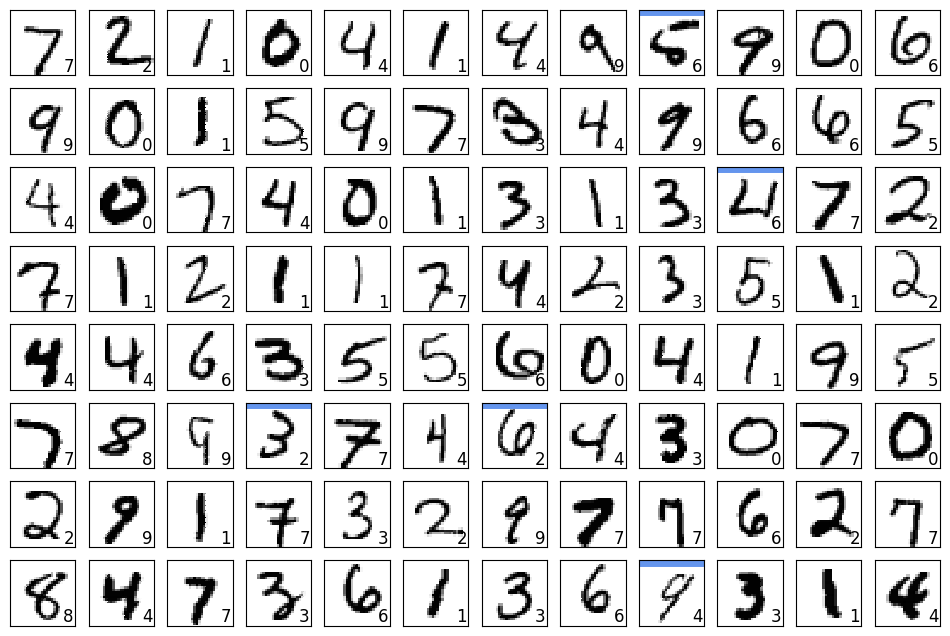

In [15]:
# 실제 테스트 데이터를 입력했을 때 모델의 출력
def show_prediction():
    n_show = 96
    y = model_relu.predict(x_test) # (A) x_test 전체에 대한 모델의 출력 y 를 얻을 수 있다.
    plt.figure(figsize = (12, 8))
    plt.gray()
    wrong_answer = 0
    # 그중 처음 96개 분량을 이미지로 출력, 파란색 가로줄은 오인식일 경우를 나타낸다.
    for i in range(n_show):
        plt.subplot(8, 12, i + 1)
        x = x_test[i, :]
        x = x.reshape(28, 28)
        plt.pcolor(1 - x)
        wk = y[i, :] # i 번째 출력 레이블을 가져온다 
        prediction = np.argmax(wk)  # wk 에서 값이 가장 큰 요소의 인덱스 값을 가져온다 = 정답 레이블의 번호 0 ~ 9 중 하나
        plt.text(22, 25.5, "%d" % prediction, fontsize = 12)
        
        if prediction != np.argmax(y_test[i, :]): # 예측 결과(prediction) 과 y_test가 일치하지 않은 경우 상단에 파란색 줄을 긋는다.
            plt.plot([0, 27], [1, 1], color ='cornflowerblue', linewidth = 5)
            wrong_answer = wrong_answer + 1
            
        plt.xlim(0, 27)
        plt.ylim(27, 0)
        plt.xticks([], "")
        plt.yticks([], "")
    print("Total wrong answer: {0: d} / 96" .format(wrong_answer))
        
# 메인
show_prediction()
plt.show()


## CNN 입력 데이터 준비

In [16]:
# MNIST 데이터셋 불러오기
import numpy as np
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train.reshape(60000, 28, 28, 1) # 데이터 하나의 shape (28, 28, 1)
x_train = x_train.astype('float32')
x_train = x_train / 255
x_test = x_test.reshape(10000, 28, 28, 1)
x_test = x_test.astype('float32')
x_test = x_test / 255

num_classes = 10
y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)


## CNN을 이용한 MNIST 데이터셋 분류 #1


In [17]:
# 2층 합성곱 신경망 구현
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dense, Activation, Flatten
from tensorflow.keras.optimizers import Adam

np.random.seed(1)

model_cnn = Sequential()
model_cnn.add(Conv2D(8, (3, 3), padding='same',
                     input_shape=(28, 28, 1), activation='relu'))
model_cnn.add(Flatten())
model_cnn.add(Dense(10, activation='softmax'))
model_cnn.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])


In [18]:
model_cnn.summary()


Model: "sequential_2"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 conv2d (Conv2D)             (None, 28, 28, 8)         80        


 flatten (Flatten)           (None, 6272)              0         


 dense_4 (Dense)             (None, 10)                62730     


Total params: 62,810


Trainable params: 62,810


Non-trainable params: 0


_________________________________________________________________


In [19]:
# 학습
start_time = time.time()
history = model_cnn.fit(x_train, y_train, epochs=10, batch_size=1000, verbose=0,
                        validation_split=1/12)
print("computation time: {:.3f} sec".format(time.time() - start_time))


computation time: 19.140 sec


## CNN 학습 곡선

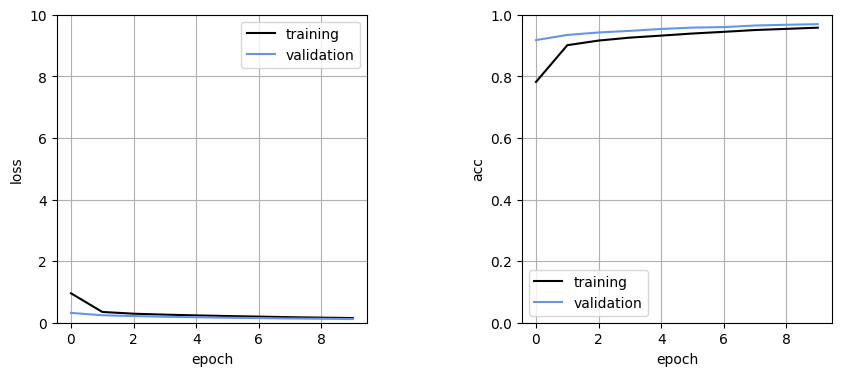

In [20]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize = (10, 4))
plt.subplots_adjust(wspace = 0.5)

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label = 'training', color = 'black')
plt.plot(history.history['val_loss'], label = 'validation', color ='cornflowerblue')
plt.ylim(0, 10)
plt.legend()
plt.grid()
plt.xlabel('epoch')
plt.ylabel('loss')

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label = 'training', color = 'black')
plt.plot(history.history['val_accuracy'], label = 'validation', color = 'cornflowerblue')
plt.ylim(0, 1)
plt.legend()
plt.grid()
plt.xlabel('epoch')
plt.ylabel('acc')
plt.show()


## CNN 예측 결과

  1/313 [..............................] - ETA: 10s

 56/313 [====>.........................] - ETA: 0s 

114/313 [=========>....................] - ETA: 0s

173/313 [===============>..............] - ETA: 0s

235/313 [=====================>........] - ETA: 0s

287/313 [==========================>...] - ETA: 0s

313/313 [==============================] - 0s 889us/step


Total wrong answer:  3 / 96


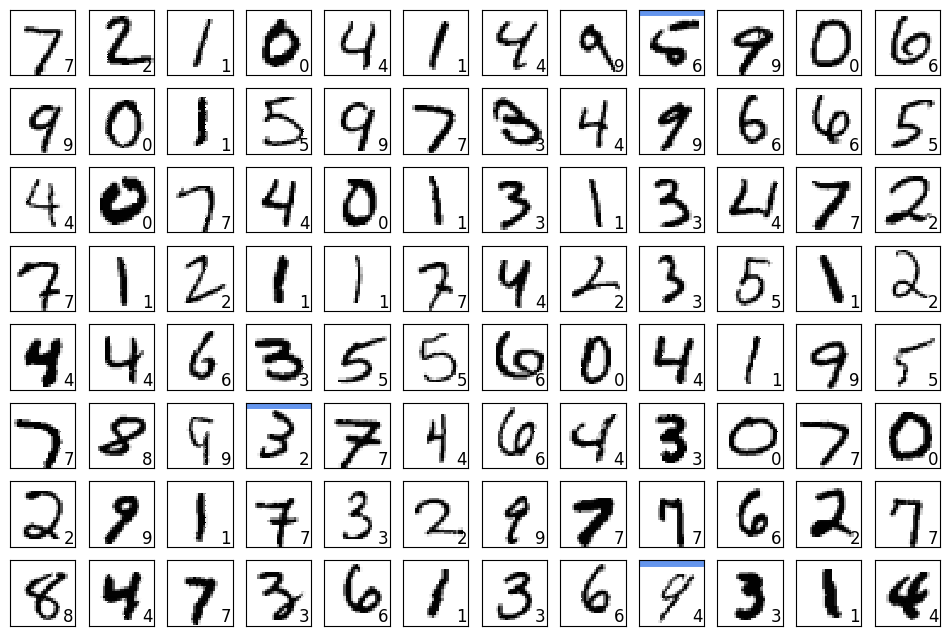

In [21]:
# 실제 테스트 데이터를 입력했을 때 모델의 출력
def show_prediction():
    n_show = 96
    y = model_cnn.predict(x_test) # (A) x_test 전체에 대한 모델의 출력 y 를 얻을 수 있다.
    plt.figure(figsize = (12, 8))
    plt.gray()
    wrong_answer = 0
    # 그중 처음 96개 분량을 이미지로 출력, 파란색 가로줄은 오인식일 경우를 나타낸다.
    for i in range(n_show):
        plt.subplot(8, 12, i + 1)
        x = x_test[i, :]
        x = x.reshape(28, 28)
        plt.pcolor(1 - x)
        wk = y[i, :] # i 번째 출력 레이블을 가져온다 
        prediction = np.argmax(wk)  # wk 에서 값이 가장 큰 요소의 인덱스 값을 가져온다 = 정답 레이블의 번호 0 ~ 9 중 하나
        plt.text(22, 25.5, "%d" % prediction, fontsize = 12)
        
        if prediction != np.argmax(y_test[i, :]): # 예측 결과(prediction) 과 y_test가 일치하지 않은 경우 상단에 파란색 줄을 긋는다.
            plt.plot([0, 27], [1, 1], color ='cornflowerblue', linewidth = 5)
            wrong_answer = wrong_answer + 1
            
        plt.xlim(0, 27)
        plt.ylim(27, 0)
        plt.xticks([], "")
        plt.yticks([], "")
    print("Total wrong answer: {0: d} / 96" .format(wrong_answer))
        
# 메인
show_prediction()
plt.show()


## 합성곱 필터 확인

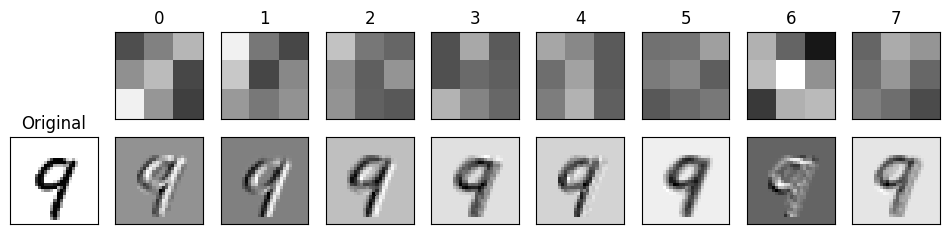

In [22]:
# 필터 리스트
plt.figure(figsize = (12, 2.5))
plt.gray()
plt.subplots_adjust(wspace = 0.2, hspace = 0.2)
plt.subplot(2, 9, 10)
id_img = 12
x_img = x_test[id_img, : , : , 0]
img_h = 28
img_w = 28
x_img = x_img.reshape(img_h, img_w)
plt.pcolor(-x_img)
plt.xlim(0, img_h)
plt.ylim(img_w, 0)
plt.xticks([], "")
plt.yticks([], "")
plt.title("Original")

# layers[0] 번째 레이어의 매개변수를 갖고오는 메서드
# get_weights()[0] 은 가중치 매개변수(conv 에서는 커널의 weight)
# get_weights()[1] 은 바이어스의 매개변수를 갖고온다
w = model_cnn.layers[0].get_weights()[0]
max_w = np.max(w)
min_w = np.min(w)

for i in range(8):
    plt.subplot(2, 9, i + 2)
    w1 = w[:, :, 0, i] # 0 ~ 7(총 여덟개) 의 필터를 순차적으로 가져온다. w.shape : (3, 3, 1, 8)
    w1 = w1.reshape(3, 3)
    plt.pcolor(-w1, vmin = min_w, vmax = max_w)
    plt.xlim(0, 3)
    plt.ylim(3, 0)
    plt.xticks([], "")
    plt.yticks([], "")
    plt.title("%d" %i)
    
    # 필터 처리
    plt.subplot(2, 9, i + 11)
    out_img = np.zeros_like(x_img)
    
    for ih in range(img_h - 3):
        for iw in range(img_w - 3):
            img_part = x_img[ih : ih + 3, iw: iw +3]
            out_img[ih + 1, iw + 1] = np.dot(img_part.reshape(-1), w1.reshape(-1))
    
    plt.pcolor(-out_img)
    plt.xlim(0, img_w)
    plt.ylim(img_h, 0)
    plt.xticks([], "")
    plt.yticks([], "")

plt.show()
# 9의 이미지에 각각의 필터를 적용한 이미지
# 작은 값은 흰색, 큰 값은 검은색 으로 나타남
# 2번 필터는 가로줄 아래쪽 엣지를 강조
# 7번 필터는 가로 윗쪽 엣지를 강조


## CNN을 이용한 MNIST 데이터셋 분류 #2


In [23]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

np.random.seed(1)

model_cnn_2 = Sequential()
model_cnn_2.add(Conv2D(16, (3, 3), input_shape=(28, 28, 1), padding='same', activation='relu'))
model_cnn_2.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
model_cnn_2.add(MaxPooling2D(pool_size=(2, 2))) # 최대 풀링층 2 x 2
model_cnn_2.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
model_cnn_2.add(MaxPooling2D(pool_size=(2, 2))) # 최대 풀링층 2 x 2
model_cnn_2.add(Dropout(0.25)) # Dropout 수행으로 0.25는 학습 중 제외하는 뉴런의 비율
model_cnn_2.add(Flatten())
model_cnn_2.add(Dense(128, activation='relu'))
model_cnn_2.add(Dropout(0.25)) # Dropout
model_cnn_2.add(Dense(num_classes, activation='softmax'))

model_cnn_2.compile(loss='categorical_crossentropy', optimizer=Adam(), metrics=['accuracy'])


In [24]:
model_cnn_2.summary()


Model: "sequential_3"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 conv2d_1 (Conv2D)           (None, 28, 28, 16)        160       


 conv2d_2 (Conv2D)           (None, 28, 28, 32)        4640      


...

 dense_6 (Dense)             (None, 10)                1290      


Total params: 426,122


Trainable params: 426,122


Non-trainable params: 0


_________________________________________________________________


In [25]:
# 학습
start_time = time.time()
history = model_cnn_2.fit(x_train, y_train, epochs=30, batch_size=1000, verbose=0,
                          validation_split=1/12)
print("computation time: {:.3f} sec".format(time.time() - start_time))


computation time: 579.643 sec


## 확장 CNN 예측 결과

  1/313 [..............................] - ETA: 19s

 10/313 [..............................] - ETA: 1s 

 20/313 [>.............................] - ETA: 1s

 30/313 [=>............................] - ETA: 1s

 40/313 [==>...........................] - ETA: 1s

...

286/313 [==========================>...] - ETA: 0s

297/313 [===========================>..] - ETA: 0s

308/313 [============================>.] - ETA: 0s

313/313 [==============================] - 2s 5ms/step


Total wrong answer:  0 / 96


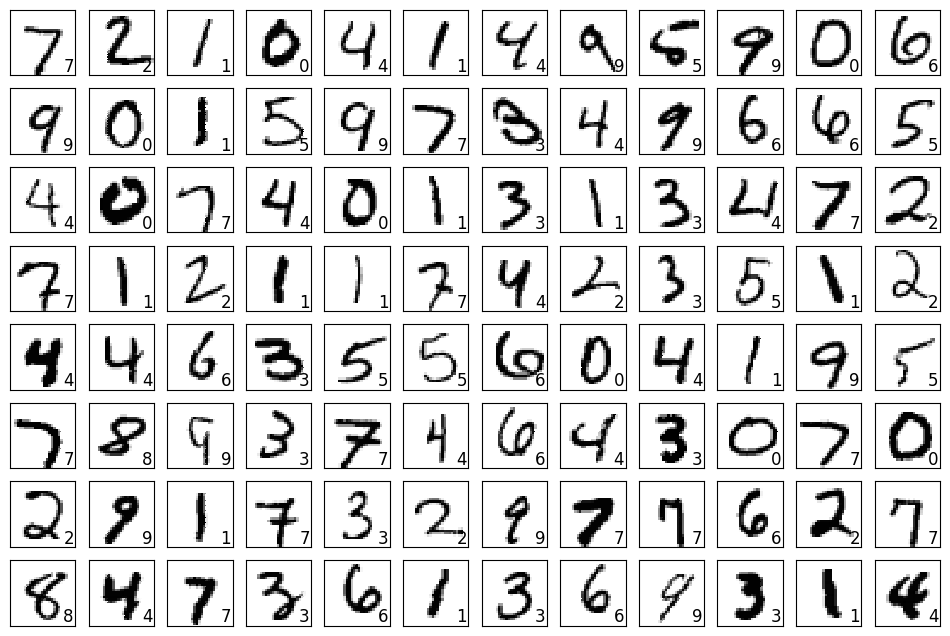

In [26]:
# 실제 테스트 데이터를 입력했을 경우 모델의 출력
def show_prediction():
    n_show = 96
    y = model_cnn_2.predict(x_test) # (A) x_test 전체에 대한 모델의 출력 y 를 얻을 수 있다.
    plt.figure(figsize = (12, 8))
    plt.gray()
    wrong_answer = 0
    # 그중 처음 96개 분량을 이미지로 출력, 파란색 가로줄은 오인식일 경우를 나타낸다.
    for i in range(n_show):
        plt.subplot(8, 12, i + 1)
        x = x_test[i, :]
        x = x.reshape(28, 28)
        plt.pcolor(1 - x)
        wk = y[i, :] # i 번째 출력 레이블을 가져온다 
        prediction = np.argmax(wk)  # wk 에서 값이 가장 큰 요소의 인덱스 값을 가져온다 = 정답 레이블의 번호 0 ~ 9 중 하나
        plt.text(22, 25.5, "%d" % prediction, fontsize = 12)
        
        if prediction != np.argmax(y_test[i, :]): # 예측 결과(prediction) 과 y_test가 일치하지 않은 경우 상단에 파란색 줄을 긋는다.
            plt.plot([0, 27], [1, 1], color ='cornflowerblue', linewidth = 5)
            wrong_answer = wrong_answer + 1
            
        plt.xlim(0, 27)
        plt.ylim(27, 0)
        plt.xticks([], "")
        plt.yticks([], "")
    print("Total wrong answer: {0: d} / 96" .format(wrong_answer))
        
# 메인
show_prediction()
plt.show()
